# LIS volume-controlled co-funding analysis
Equal-sized publication samples per year; original metric definitions and plotting retained.

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import ast
from itertools import combinations

SEED = 42
DATA_PATH = "LIS_data_cleaned_with_OND.csv"

# Publication-level sampling (NOT sampling co-funding edges).

df = pd.read_csv(DATA_PATH)

assert df["Paper_id"].is_unique, "Paper_id must identify one publication per row."

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")

df = df.dropna(subset=["Year"]).copy()

df["Year"] = df["Year"].astype(int)

df = df[df["Year"].between(2014, 2024)].copy()

def parse_funders(x):
    if pd.isna(x): return []
    x = str(x).strip()
    if x in ("", "[]", "nan", "None", "NaN"): return []
    try:
        value = ast.literal_eval(x)
        if isinstance(value, list):
            return [str(f).strip() for f in value if str(f).strip()]
    except (ValueError, SyntaxError):
        pass
    return [f.strip() for f in x.split(";") if f.strip()]

def make_edges(papers):
    records = []
    for paper_id, year, source, details in papers[["Paper_id", "Year", "Source title", "Funding_Details_OND"]].itertuples(index=False, name=None):
        funders = sorted(set(parse_funders(details)))
        for a, b in combinations(funders, 2):
            records.append((paper_id, year, source, a, b))
    return pd.DataFrame(records, columns=["Paper_id", "Year", "Source title", "Funder_A", "Funder_B"])

# Minimum publication count among the years, using ALL publications.

year_counts = df.groupby("Year").size()
N_YEAR = int(year_counts.min())

print("Annual publication counts:\n", year_counts.to_string())
print("Equal publications sampled per year:", N_YEAR)

annual_sample = df.groupby("Year", group_keys=False).apply(lambda x: x.sample(n=N_YEAR, random_state=SEED))

annual_sample[["Paper_id", "Year"]].to_csv("LIS_volume_control_annual_sample_ids.csv", index=False)

paper_edge_list = make_edges(annual_sample)

print("Sampled publications:", len(annual_sample), "| co-funding pair occurrences:", len(paper_edge_list))


Annual publication counts:
 Year
2014     5300
2015     5458
2016     6035
2017     6191
2018     6596
2019     6845
2020     8154
2021     7913
2022     8476
2023     8801
2024    11025
Equal publications sampled per year: 5300
Sampled publications: 58300 | co-funding pair occurrences: 75617


## Annual network statistics

In [3]:
# ============================================================
# Table 3.6
# Network Statistics Over Time
#
# Unit of analysis:
# Annual co-funding networks
#
# Node:
# Funding organization
#
# Edge:
# Co-funding relationship between two funders
#
# Edge weight:
# Number of co-funded papers in a given year
# ============================================================

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# Function:
# Build annual co-funding network from paper-level edge list
# ------------------------------------------------------------

def build_annual_network(edge_df, year):

    # Select edges observed in the given year
    year_edges = edge_df[
        edge_df["Year"] == year
    ].copy()

    # Aggregate repeated co-funding pairs within the year
    annual_weighted_edges = (
        year_edges
        .groupby(["Funder_A", "Funder_B"])
        .size()
        .reset_index(name="Weight")
    )

    # Create graph
    G_year = nx.Graph()

    for _, row in annual_weighted_edges.iterrows():
        G_year.add_edge(
            row["Funder_A"],
            row["Funder_B"],
            weight=row["Weight"]
        )

    return G_year


# ------------------------------------------------------------
# Function:
# Calculate network statistics
# ------------------------------------------------------------

def calculate_network_statistics(G, year):

    nodes = G.number_of_nodes()
    edges = G.number_of_edges()

    # If the network is empty
    if nodes == 0:
        return {
            "Year": year,
            "Nodes": 0,
            "Edges": 0,
            "Density": 0,
            "Components": 0,
            "Largest Component Size": 0,
            "Largest Component Share (%)": 0,
            "Avg Degree": 0,
            "Avg Weighted Degree": 0,
            "Avg Clustering": 0,
            "Avg Weighted Clustering": 0
        }

    # Connected components
    components = list(nx.connected_components(G))

    num_components = len(components)

    largest_component_size = len(
        max(components, key=len)
    )

    largest_component_share = (
        largest_component_size / nodes * 100
    )

    # Average degree
    avg_degree = (
        sum(dict(G.degree()).values()) / nodes
    )

    # Average weighted degree
    avg_weighted_degree = (
        sum(dict(G.degree(weight="weight")).values()) / nodes
    )

    # Density
    density = nx.density(G)

    # Clustering coefficients
    avg_clustering = nx.average_clustering(G)

    avg_weighted_clustering = nx.average_clustering(
        G,
        weight="weight"
    )

    return {
        "Year": year,
        "Nodes": nodes,
        "Edges": edges,
        "Density": density,
        "Components": num_components,
        "Largest Component Size": largest_component_size,
        "Largest Component Share (%)": largest_component_share,
        "Avg Degree": avg_degree,
        "Avg Weighted Degree": avg_weighted_degree,
        "Avg Clustering": avg_clustering,
        "Avg Weighted Clustering": avg_weighted_clustering
    }


# ------------------------------------------------------------
# Create annual network statistics table
# ------------------------------------------------------------

years = sorted(
    paper_edge_list["Year"]
    .dropna()
    .unique()
)

annual_network_stats = []

for year in years:

    G_year = build_annual_network(
        paper_edge_list,
        year
    )

    stats = calculate_network_statistics(
        G_year,
        year
    )

    annual_network_stats.append(stats)

table_3_6_network_stats = pd.DataFrame(
    annual_network_stats
)

# ------------------------------------------------------------
# Round values for dissertation table
# ------------------------------------------------------------

table_3_6_network_stats = table_3_6_network_stats.round({
    "Density": 6,
    "Largest Component Share (%)": 2,
    "Avg Degree": 3,
    "Avg Weighted Degree": 3,
    "Avg Clustering": 3,
    "Avg Weighted Clustering": 4
})

# ------------------------------------------------------------
# Display Table 3.6
# ------------------------------------------------------------

table_3_6_network_stats

,Year,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,2014,802,2585,0.008048,32,717,89.40,6.446,7.930,0.681,0.0178
1,2015,745,3864,0.013942,46,626,84.03,10.373,11.715,0.683,0.0218
2,2016,937,3839,0.008755,25,870,92.85,8.194,9.893,0.733,0.0185
3,2017,1204,4988,0.006888,44,1104,91.69,8.286,9.947,0.696,0.0186
4,2018,1740,6823,0.004510,66,1581,90.86,7.843,9.497,0.693,0.0219
5,2019,1820,8158,0.004928,62,1658,91.10,8.965,10.612,0.694,0.0217
6,2020,1753,6342,0.004130,64,1599,91.22,7.236,8.759,0.666,0.0191
7,2021,1699,5899,0.004090,69,1541,90.70,6.944,8.393,0.670,0.0161
8,2022,1742,7702,0.005079,74,1547,88.81,8.843,10.289,0.690,0.0132
9,2023,2017,6999,0.003442,90,1806,89.54,6.940,8.763,0.665,0.0123


In [4]:
table_3_6_network_stats.to_csv("LIS_volume_control_annual_network_stats.csv", index=False)
table_3_6_network_stats

,Year,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,2014,802,2585,0.008048,32,717,89.40,6.446,7.930,0.681,0.0178
1,2015,745,3864,0.013942,46,626,84.03,10.373,11.715,0.683,0.0218
2,2016,937,3839,0.008755,25,870,92.85,8.194,9.893,0.733,0.0185
3,2017,1204,4988,0.006888,44,1104,91.69,8.286,9.947,0.696,0.0186
4,2018,1740,6823,0.004510,66,1581,90.86,7.843,9.497,0.693,0.0219
5,2019,1820,8158,0.004928,62,1658,91.10,8.965,10.612,0.694,0.0217
6,2020,1753,6342,0.004130,64,1599,91.22,7.236,8.759,0.666,0.0191
7,2021,1699,5899,0.004090,69,1541,90.70,6.944,8.393,0.670,0.0161
8,2022,1742,7702,0.005079,74,1547,88.81,8.843,10.289,0.690,0.0132
9,2023,2017,6999,0.003442,90,1806,89.54,6.940,8.763,0.665,0.0123


## Annual trend figure

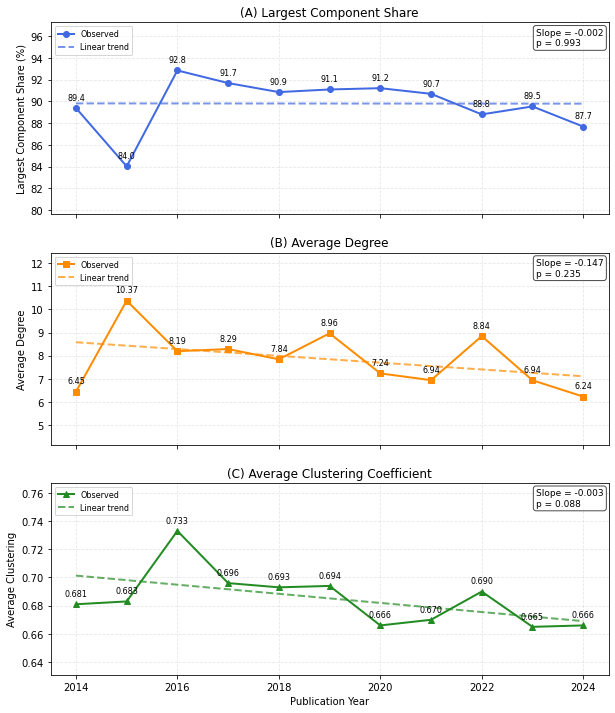

,Metric,Slope,p-value
0,Largest Component Share (%),-0.0023,0.9927
1,Average Degree,-0.1466,0.2350
2,Average Clustering,-0.0032,0.0880


In [8]:
# ============================================================
# Figure 3.10
# Temporal Change in LIS Co-funding Network Structure
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
#
# Features:
# 1. Expanded y-axis range
# 2. Value labels added to each point
# 3. Different colors for each metric
# 4. Linear trend line added to each panel
# 5. Slope and p-value displayed in each panel
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress

plot_df = table_3_6_network_stats.copy()

# ------------------------------------------------------------
# Helper function for each panel
# ------------------------------------------------------------

def plot_metric_with_trend(
    ax,
    x,
    y,
    color,
    marker,
    title,
    ylabel,
    value_format
):

    # Observed line
    ax.plot(
        x,
        y,
        marker=marker,
        linewidth=2,
        color=color,
        label="Observed"
    )

    # Linear trend
    slope, intercept, r_value, p_value, std_err = linregress(
        x,
        y
    )

    trend = intercept + slope * x

    ax.plot(
        x,
        trend,
        linestyle="--",
        linewidth=2,
        color=color,
        alpha=0.7,
        label="Linear trend"
    )

    # Value labels
    for x_val, y_val in zip(x, y):
        ax.annotate(
            value_format.format(y_val),
            (x_val, y_val),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=8
        )

    # Add padding to y-axis
    y_range = y.max() - y.min()

    if y_range == 0:
        padding = y.max() * 0.20
    else:
        padding = y_range * 0.50

    ax.set_ylim(
        y.min() - padding,
        y.max() + padding
    )

    # Add slope and p-value
    ax.text(
        0.87,
        0.97,
        f"Slope = {slope:.3f}\n"
        f"p = {p_value:.3f}",
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.7
        )
    )

    ax.set_ylabel(ylabel)

    ax.set_title(title)

    ax.grid(
        alpha=0.3,
        linestyle="--"
    )

    ax.legend(
        loc="upper left",
        frameon=True,
        fontsize=8
    )

    return slope, p_value


# ------------------------------------------------------------
# Create 3-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 12),
    sharex=True
)

x = plot_df["Year"].values

# Panel A
slope_lcc, p_lcc = plot_metric_with_trend(
    ax=axes[0],
    x=x,
    y=plot_df["Largest Component Share (%)"].values,
    color="royalblue",
    marker="o",
    title="(A) Largest Component Share",
    ylabel="Largest Component Share (%)",
    value_format="{:.1f}"
)

# Panel B
slope_degree, p_degree = plot_metric_with_trend(
    ax=axes[1],
    x=x,
    y=plot_df["Avg Degree"].values,
    color="darkorange",
    marker="s",
    title="(B) Average Degree",
    ylabel="Average Degree",
    value_format="{:.2f}"
)

# Panel C
slope_clustering, p_clustering = plot_metric_with_trend(
    ax=axes[2],
    x=x,
    y=plot_df["Avg Clustering"].values,
    color="forestgreen",
    marker="^",
    title="(C) Average Clustering Coefficient",
    ylabel="Average Clustering",
    value_format="{:.3f}"
)

axes[2].set_xlabel("Publication Year")

# ------------------------------------------------------------
# Overall title
# ------------------------------------------------------------

# fig.suptitle(
#     "Volume-Controlled Temporal LIS Co-funding Network",
#     fontsize=14,
#     y=0.99
# )

# plt.tight_layout(
#     rect=[0, 0, 1, 0.97]
# )

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_Volume_Control_Temporal_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_Volume_Control_Temporal_LIS.pdf",
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Optional: Create trend summary table
# ------------------------------------------------------------

figure_3_10_trend_summary = pd.DataFrame({
    "Metric": [
        "Largest Component Share (%)",
        "Average Degree",
        "Average Clustering"
    ],
    "Slope": [
        slope_lcc,
        slope_degree,
        slope_clustering
    ],
    "p-value": [
        p_lcc,
        p_degree,
        p_clustering
    ]
})

figure_3_10_trend_summary = figure_3_10_trend_summary.round(4)

figure_3_10_trend_summary

## Quartile-controlled comparison

In [10]:
# Separate quartile comparison: draw from ALL publications, not the annual sample.

journal_df = pd.read_csv("journal_list.csv")
journal_df["Journal_name_clean"] = journal_df["Journal_name"].astype(str).str.strip().str.lower()
journal_df["Quartile"] = pd.qcut(journal_df["Ranking"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])

# Verify unique journal mapping before merging to avoid duplicate publication rows.

assert journal_df["Journal_name_clean"].is_unique, "Duplicate journal names in journal_list.csv; resolve before merging."

df["Source_title_clean"] = df["Source title"].astype(str).str.strip().str.lower()

df_quartile = df.merge(journal_df[["Journal_name_clean", "Quartile"]], left_on="Source_title_clean", right_on="Journal_name_clean", how="left", validate="many_to_one")

print("Unmatched publication quartiles:", int(df_quartile["Quartile"].isna().sum()))

# Do not silently exclude unmatched publications.

assert df_quartile["Quartile"].notna().all(), "Resolve unmatched journals before quartile comparison."

quartile_counts = df_quartile.groupby("Quartile", observed=True).size().reindex(["Q1", "Q2", "Q3", "Q4"])

assert quartile_counts.notna().all() and (quartile_counts > 0).all()

N_QUARTILE = int(quartile_counts.min())

print("Publication counts by quartile:\n", quartile_counts.to_string())
print("Equal publications sampled per quartile:", N_QUARTILE)

quartile_sample = df_quartile.groupby("Quartile", group_keys=False).apply(lambda x: x.sample(n=N_QUARTILE, random_state=SEED))

quartile_sample[["Paper_id", "Quartile"]].to_csv("LIS_volume_control_quartile_sample_ids.csv", index=False)

paper_edge_quartile = make_edges(quartile_sample).merge(quartile_sample[["Paper_id", "Quartile"]], on="Paper_id", how="left", validate="many_to_one")

print("Sampled publications:", len(quartile_sample), "| co-funding pair occurrences:", len(paper_edge_quartile))


Unmatched publication quartiles: 0
Publication counts by quartile:
 Quartile
Q1    40645
Q2    13683
Q3    14731
Q4    11735
Equal publications sampled per quartile: 11735
Sampled publications: 46940 | co-funding pair occurrences: 44381


In [11]:
# ============================================================
# Function:
# Build quartile-specific co-funding network
# ============================================================

def build_quartile_network(edge_df, quartile):

    q_edges = edge_df[
        edge_df["Quartile"] == quartile
    ].copy()

    q_weighted_edges = (
        q_edges
        .groupby(["Funder_A", "Funder_B"])
        .size()
        .reset_index(name="Weight")
    )

    G_q = nx.Graph()

    for _, row in q_weighted_edges.iterrows():
        G_q.add_edge(
            row["Funder_A"],
            row["Funder_B"],
            weight=row["Weight"]
        )

    return G_q


# ============================================================
# Function:
# Calculate network statistics
# ============================================================

def calculate_quartile_network_statistics(G, quartile):

    nodes = G.number_of_nodes()
    edges = G.number_of_edges()

    if nodes == 0:
        return {
            "Quartile": quartile,
            "Nodes": 0,
            "Edges": 0,
            "Density": 0,
            "Components": 0,
            "Largest Component Size": 0,
            "Largest Component Share (%)": 0,
            "Avg Degree": 0,
            "Avg Weighted Degree": 0,
            "Avg Clustering": 0,
            "Avg Weighted Clustering": 0
        }

    components = list(nx.connected_components(G))

    num_components = len(components)

    largest_component_size = len(
        max(components, key=len)
    )

    largest_component_share = (
        largest_component_size / nodes * 100
    )

    avg_degree = (
        sum(dict(G.degree()).values()) / nodes
    )

    avg_weighted_degree = (
        sum(dict(G.degree(weight="weight")).values()) / nodes
    )

    density = nx.density(G)

    avg_clustering = nx.average_clustering(G)

    avg_weighted_clustering = nx.average_clustering(
        G,
        weight="weight"
    )

    return {
        "Quartile": quartile,
        "Nodes": nodes,
        "Edges": edges,
        "Density": density,
        "Components": num_components,
        "Largest Component Size": largest_component_size,
        "Largest Component Share (%)": largest_component_share,
        "Avg Degree": avg_degree,
        "Avg Weighted Degree": avg_weighted_degree,
        "Avg Clustering": avg_clustering,
        "Avg Weighted Clustering": avg_weighted_clustering
    }

In [12]:
# ============================================================
# Create Table 3.7
# Network Comparison by Journal Quartile
# ============================================================

quartiles = ["Q1", "Q2", "Q3", "Q4"]

quartile_network_stats = []

quartile_graphs = {}

for q in quartiles:

    G_q = build_quartile_network(
        paper_edge_quartile,
        q
    )

    quartile_graphs[q] = G_q

    stats = calculate_quartile_network_statistics(
        G_q,
        q
    )

    quartile_network_stats.append(stats)

table_3_7_quartile_network_stats = pd.DataFrame(
    quartile_network_stats
)

table_3_7_quartile_network_stats = (
    table_3_7_quartile_network_stats
    .round({
        "Density": 6,
        "Largest Component Share (%)": 2,
        "Avg Degree": 3,
        "Avg Weighted Degree": 3,
        "Avg Clustering": 3,
        "Avg Weighted Clustering": 4
    })
)

table_3_7_quartile_network_stats

,Quartile,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,Q1,3322,16087,0.002916,80,3149,94.79,9.685,12.874,0.668,0.0061
1,Q2,2085,6476,0.002981,114,1796,86.14,6.212,7.273,0.607,0.0198
2,Q3,2354,8414,0.003038,110,2082,88.45,7.149,8.729,0.645,0.0093
3,Q4,1478,4424,0.004053,81,1294,87.55,5.986,6.958,0.651,0.0248


In [13]:
table_3_7_quartile_network_stats.to_csv("LIS_volume_control_quartile_network_stats.csv", index=False)
table_3_7_quartile_network_stats

,Quartile,Nodes,Edges,Density,Components,Largest Component Size,Largest Component Share (%),Avg Degree,Avg Weighted Degree,Avg Clustering,Avg Weighted Clustering
0,Q1,3322,16087,0.002916,80,3149,94.79,9.685,12.874,0.668,0.0061
1,Q2,2085,6476,0.002981,114,1796,86.14,6.212,7.273,0.607,0.0198
2,Q3,2354,8414,0.003038,110,2082,88.45,7.149,8.729,0.645,0.0093
3,Q4,1478,4424,0.004053,81,1294,87.55,5.986,6.958,0.651,0.0248


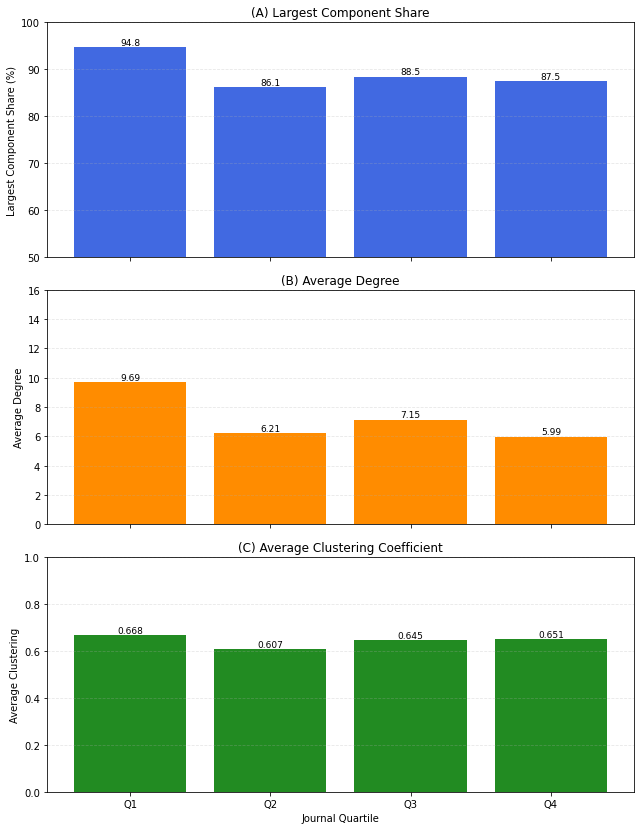

In [14]:
# ============================================================
# Figure 3.11
# Network Comparison by Journal Quartile
#
# Panel A: Largest Component Share (%)
# Panel B: Average Degree
# Panel C: Average Clustering Coefficient
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

plot_df = table_3_7_quartile_network_stats.copy()

# Ensure quartile order
plot_df["Quartile"] = pd.Categorical(
    plot_df["Quartile"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

plot_df = plot_df.sort_values("Quartile")

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(9, 12),
    sharex=True
)

# ------------------------------------------------------------
# Helper function
# ------------------------------------------------------------

def plot_quartile_bar(
    ax,
    x,
    y,
    title,
    ylabel,
    value_format,
    color
):

    bars = ax.bar(
        x,
        y,
        color=color
    )

    for bar, value in zip(bars, y):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            value_format.format(value),
            ha="center",
            va="bottom",
            fontsize=9
        )

    padding = (max(y) - min(y)) * 0.20

    ax.set_ylim(
        min(y) - padding,
        max(y) + padding
    )

    ax.set_title(title)

    ax.set_ylabel(ylabel)

    ax.grid(
        axis="y",
        alpha=0.3,
        linestyle="--"
    )


# Panel A
plot_quartile_bar(
    ax=axes[0],
    x=plot_df["Quartile"],
    y=plot_df["Largest Component Share (%)"],
    title="(A) Largest Component Share",
    ylabel="Largest Component Share (%)",
    value_format="{:.1f}",
    color="royalblue"
)

# Panel B
plot_quartile_bar(
    ax=axes[1],
    x=plot_df["Quartile"],
    y=plot_df["Avg Degree"],
    title="(B) Average Degree",
    ylabel="Average Degree",
    value_format="{:.2f}",
    color="darkorange"
)

# Panel C
plot_quartile_bar(
    ax=axes[2],
    x=plot_df["Quartile"],
    y=plot_df["Avg Clustering"],
    title="(C) Average Clustering Coefficient",
    ylabel="Average Clustering",
    value_format="{:.3f}",
    color="forestgreen"
)

axes[2].set_xlabel("Journal Quartile")

# fig.suptitle(
#     "Figure 3.11. Network Comparison by Journal Quartile",
#     fontsize=14,
#     y=0.99
# )

# ------------------------------------------------------------
# Set consistent y-axis ranges
# ------------------------------------------------------------

# Panel A
axes[0].set_ylim(50, 100)

# Panel B
axes[1].set_ylim(0, 16)

# Panel C
axes[2].set_ylim(0, 1)


plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    "Figure_Volume_Control_Quartile_LIS.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Figure_Volume_Control_Quartile_LIS.pdf",
    bbox_inches="tight"
)

plt.show()